In [1]:
import torch
import torch.nn as nn

In [2]:
z = torch.tensor([[-2],[0],[2]],dtype = torch.float32)
res = torch.sigmoid(z)
print(res)
predictions = (res >= 0.5).long()
print(predictions)

tensor([[0.1192],
        [0.5000],
        [0.8808]])
tensor([[0],
        [1],
        [1]])


In [3]:
y = torch.tensor([[0],[1],[1]],dtype = torch.float32)
loss = (-(y * torch.log(res) + (torch.sub(1,y) *torch.log(torch.sub(1,res))))).mean()
print(loss)

tensor(0.3157)


In [4]:
criterion = torch.nn.BCEWithLogitsLoss()
loss_api =criterion(z,y)
criterion_each = torch.nn.BCEWithLogitsLoss(reduction="none")
loss_each_api = criterion_each(z, y)

print(loss_api)
print(loss_each_api)
print(torch.allclose(loss, loss_api))

tensor(0.3157)
tensor([[0.1269],
        [0.6931],
        [0.1269]])
True


In [6]:
x = torch.tensor([
    [-2, -1],
    [-1, -2],
    [-2, -2],
    [-1,  0],
    [ 1,  0],
    [ 2,  1],
    [ 1,  2],
    [ 2,  2],
], dtype=torch.float32)

y = torch.tensor([
    [0],
    [0],
    [0],
    [0],
    [1],
    [1],
    [1],
    [1],
], dtype=torch.float32)

layer = nn.Linear(2,1)
optimizer = torch.optim.SGD(layer.parameters(),lr = 0.1)
loss_api = torch.nn.BCEWithLogitsLoss()
for step in range(500):
    optimizer.zero_grad(set_to_none = True)
    y_pred = layer(x)
    
    loss = loss_api(y_pred,y)
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        y_pred = layer(x)
        loss = loss_api(y_pred,y)
        
        if (step + 1) % 100 == 0:
            print(f"Step {step + 1}: loss={loss.item():.6f}")
            print("Logits:", y_pred.tolist())
            



Step 100: loss=0.073317
Logits: [[-3.7124722003936768], [-3.839036226272583], [-5.112659931182861], [-1.0386594533920288], [1.5085889101028442], [4.182401657104492], [4.308965682983398], [5.582589626312256]]
Step 200: loss=0.042156
Logits: [[-4.9645209312438965], [-4.653369903564453], [-6.4633378982543945], [-1.6557369232177734], [1.9641985893249512], [5.272983074188232], [4.961832046508789], [6.7718000411987305]]
Step 300: loss=0.029761
Logits: [[-5.741682052612305], [-5.133195877075195], [-7.288222312927246], [-2.0401158332824707], [2.269937515258789], [5.971504211425781], [5.363018035888672], [7.518044471740723]]
Step 400: loss=0.023017
Logits: [[-6.307907581329346], [-5.473326206207275], [-7.8846611976623535], [-2.319819688796997], [2.502849817276001], [6.49093770980835], [5.656356334686279], [8.0676908493042]]
Step 500: loss=0.018764
Logits: [[-6.753531455993652], [-5.736384868621826], [-8.351943016052246], [-2.539562463760376], [2.6915533542633057], [6.905522346496582], [5.888375

In [7]:
res = torch.sigmoid(y_pred)
print(res)   
print((res >= 0.5).long())

tensor([[1.1654e-03],
        [3.2160e-03],
        [2.3588e-04],
        [7.3131e-02],
        [9.3653e-01],
        [9.9900e-01],
        [9.9724e-01],
        [9.9980e-01]])
tensor([[0],
        [0],
        [0],
        [0],
        [1],
        [1],
        [1],
        [1]])


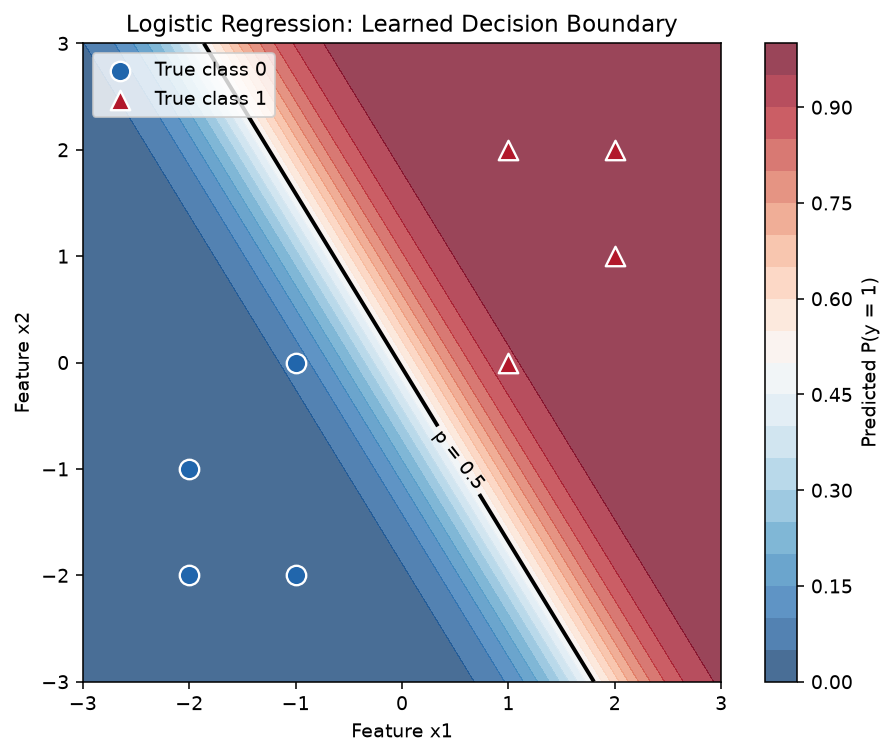

Decision boundary: 2.6156 * x1 + 1.5984 * x2 + (0.0760) = 0


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# 根据训练数据确定绘图范围。
points = x.detach().cpu().numpy()
labels = y.detach().cpu().numpy().reshape(-1)

x1_values = np.linspace(points[:, 0].min() - 1,
                        points[:, 0].max() + 1, 300)
x2_values = np.linspace(points[:, 1].min() - 1,
                        points[:, 1].max() + 1, 300)

xx, yy = np.meshgrid(x1_values, x2_values)

# 将平面上的网格点组成一个 batch，每个点有两个特征。
grid = torch.tensor(
    np.column_stack([xx.ravel(), yy.ravel()]),
    dtype=layer.weight.dtype,
    device=layer.weight.device,
)

# 用训练好的模型预测整个平面上的概率。
with torch.no_grad():
    probabilities = torch.sigmoid(layer(grid))
    probability_map = probabilities.cpu().numpy().reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5.5), dpi=140)

background = ax.contourf(
    xx, yy, probability_map,
    levels=np.linspace(0, 1, 21),
    cmap="RdBu_r",
    vmin=0, vmax=1,
    alpha=0.75,
)

# p=0.5 等价于 w1*x1 + w2*x2 + b = 0。
boundary = ax.contour(
    xx, yy, probability_map,
    levels=[0.5],
    colors="black",
    linewidths=2,
)
ax.clabel(boundary, fmt={0.5: "p = 0.5"}, fontsize=10)

for label, color, marker in [
    (0, "#2166AC", "o"),
    (1, "#B2182B", "^"),
]:
    selected = labels == label
    ax.scatter(
        points[selected, 0],
        points[selected, 1],
        color=color,
        marker=marker,
        s=100,
        edgecolors="white",
        linewidths=1.2,
        label=f"True class {label}",
        zorder=3,
    )

fig.colorbar(background, ax=ax, label="Predicted P(y = 1)")
ax.set(
    xlabel="Feature x1",
    ylabel="Feature x2",
    title="Logistic Regression: Learned Decision Boundary",
)
ax.set_aspect("equal")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

weights = layer.weight.detach().cpu().flatten().tolist()
bias = layer.bias.item()
print(
    f"Decision boundary: "
    f"{weights[0]:.4f} * x1 + {weights[1]:.4f} * x2 "
    f"+ ({bias:.4f}) = 0"
)